# Лабораторная работа 5. Перцептрон Розенблатта

**Вариант 2. Линейный тренд с шумом Лапласа, окно из шести наблюдений.**

На каждом шаге предскажем следующее значение ряда по шести уже известным. По форме предсказания это линейная регрессия из лабы 3 с несколькими признаками. Веса найдём градиентным спуском из лабы 2.

[Условие задания](../lab5.md) · [Урок с выводом формул](lab5.md) · [Лайв-кодинг](../lab5_live.ipynb)

## 1. Генерация сигнала

Берём 600 равноотстоящих моментов $t=0,\ldots,599$. Чистый тренд задаётся формулой $f(t)=0.03t-5$. К каждой точке прибавляем независимый шум Лапласа с центром $0$ и параметром масштаба $0.3$. Получаем наблюдаемый ряд $y_t=f(t)+\varepsilon_t$.

Как в лабе 1, используем отдельный генератор случайных чисел. Фиксированный seed позволяет сравнивать эксперименты на одном и том же ряде.

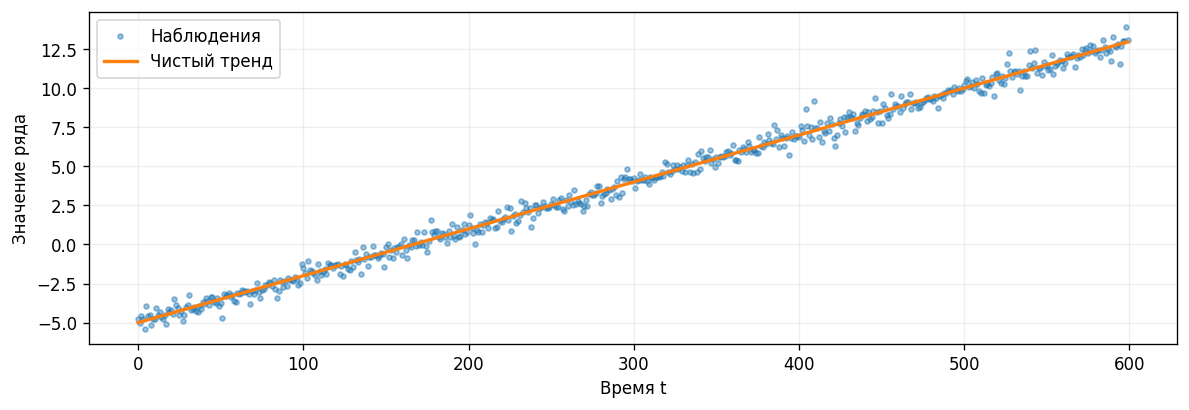

In [1]:
import numpy as np
import matplotlib.pyplot as plt

N = 600
WINDOW = 6
SPLIT_AT = int(0.8 * N)
DATA_SEED = 42

rng = np.random.default_rng(DATA_SEED)
t = np.arange(N)
clean_signal = 0.03 * t - 5
noise = rng.laplace(loc=0.0, scale=0.3, size=N)
signal = clean_signal + noise

plt.figure(figsize=(10, 3.5))
plt.scatter(t, signal, s=9, alpha=0.45, color="tab:blue", label="Наблюдения")
plt.plot(t, clean_signal, color="tab:orange", linewidth=2, label="Чистый тренд")
plt.xlabel("Время t")
plt.ylabel("Значение ряда")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 2. Окна и разделение по времени

Для прогноза $y_t$ берём строку из значений $y_{t-6},\ldots,y_{t-1}$. Один ряд превращается в таблицу. Строка содержит один пример, столбец соответствует одной позиции в окне, цель хранится отдельно.

Разрежем исходный ряд по времени в точке $t=480$. Цели с $t<480$ идут в train. В test идут цели с $t\geq480$. Первый тестовый прогноз использует $y_{474},\ldots,y_{479}$. Затем прогнозируем на один шаг вперёд, добавляя фактическое наблюдение в историю после того, как оно стало доступно.

In [2]:
def make_windows(series, size):
    X = np.array([series[end - size:end] for end in range(size, len(series))])
    y = series[size:]
    return X, y


X_demo, y_demo = make_windows(np.array([1, 2, 3, 4, 5]), 2)
print("Окна:")
print(X_demo)
print("Цели:", y_demo)

np.testing.assert_array_equal(X_demo, [[1, 2], [2, 3], [3, 4]])
np.testing.assert_array_equal(y_demo, [3, 4, 5])

Окна:
[[1 2]
 [2 3]
 [3 4]]
Цели: [3 4 5]


In [3]:
X, y = make_windows(signal, WINDOW)
target_t = t[WINDOW:]
train_mask = target_t < SPLIT_AT

X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]
t_train, t_test = target_t[train_mask], target_t[~train_mask]

print(f"Train: {X_train.shape}, время целей {t_train[0]}–{t_train[-1]}")
print(f"Test:  {X_test.shape}, время целей {t_test[0]}–{t_test[-1]}")
print("Первое тестовое окно:", X_test[0].round(3))

assert X_train.shape == (474, WINDOW) and X_test.shape == (120, WINDOW)
assert t_train[-1] == 479 and t_test[0] == 480
np.testing.assert_array_equal(X_test[0], signal[SPLIT_AT - WINDOW:SPLIT_AT])

Train: (474, 6), время целей 6–479
Test:  (120, 6), время целей 480–599
Первое тестовое окно: [9.044 9.101 9.233 9.385 9.434 9.312]


## 3. Нормализация входов

Как в лабе 4, стандартизируем каждый столбец по формуле $z_j=(x_j-\mu_j)/\sigma_j$. Средние и стандартные отклонения вычисляем по train. К test применяем те же числа. Цель $y$ оставляем в единицах исходного ряда.

In [4]:
center = X_train.mean(axis=0)
scale = X_train.std(axis=0)
Z_train = (X_train - center) / scale
Z_test = (X_test - center) / scale

print("Среднее по столбцам train:", Z_train.mean(axis=0).round(10))
print("Стандартное отклонение по столбцам train:", Z_train.std(axis=0).round(10))

np.testing.assert_allclose(Z_train.mean(axis=0), 0.0, atol=1e-12)
np.testing.assert_allclose(Z_train.std(axis=0), 1.0)

Среднее по столбцам train: [-0. -0. -0. -0. -0. -0.]
Стандартное отклонение по столбцам train: [1. 1. 1. 1. 1. 1.]


## 4. Линейный нейрон и метрики

Нейрон складывает взвешенные входы и добавляет смещение $b$. Линейная активация здесь просто возвращает полученное число.

$$
\hat y = w_1z_1 + \cdots + w_6z_6 + b.
$$

MSE и MAPE уже были в лабе 3. MSE усредняет квадраты ошибок. MAPE усредняет абсолютные относительные ошибки в процентах. В реализации ниже при точном $y_i=0$ слагаемое MAPE пропускается, а при отсутствии ненулевых целей функция возвращает `nan`. При малом ненулевом $|y_i|$ вклад точки остаётся большим.

Классический перцептрон Розенблатта применяет порог и выдаёт класс. В этой работе используется линейный нейрон для прогноза числа.

In [5]:
def predict(Z, w, b):
    return Z @ w + b


def mse(y, y_pred):
    return np.mean((y - y_pred) ** 2)


def mape(y, y_pred):
    nonzero = y != 0
    if not np.any(nonzero):
        return np.nan
    relative_errors = np.abs((y[nonzero] - y_pred[nonzero]) / y[nonzero])
    return 100 * relative_errors.mean()



# Первые две строки учебного примера после стандартизации.
Z_demo = np.array([[-1.0, -1.0], [1.0, 1.0]])
y_demo_train = y_demo[:2]
w_demo = np.array([0.5, -0.5])
b_demo = 3.0
pred_demo = predict(Z_demo, w_demo, b_demo)

np.testing.assert_allclose(pred_demo, [3.0, 3.0])
np.testing.assert_allclose(mse(y_demo_train, pred_demo), 0.5)
np.testing.assert_allclose(mape(y_demo_train, pred_demo), 12.5)
print(f"MSE: {mse(y_demo_train, pred_demo):.2f}, MAPE: {mape(y_demo_train, pred_demo):.1f}%")

MSE: 0.50, MAPE: 12.5%


## 5. Дельта-правило и обучение

Как в лабе 2, один шаг идёт по антиградиенту. Здесь потери — MSE, параметры — вектор весов и смещение. Считаем вектор ошибок $e=y-\hat y$ на всех $n$ строках train. Для одного обновления используем одну и ту же ошибку в обеих формулах.

$$
w\gets w + \eta \frac{2}{n} Z^\top e,\qquad
b\gets b + 2\eta\,\operatorname{mean}(e).
$$

В этой реализации один полный проход по train даёт одно обновление. Скорость обучения $\eta$ постоянна внутри запуска. Сохраним параметры до первого шага и после каждой эпохи, чтобы позднее посчитать метрики.

In [6]:
def delta_step(Z, y, w, b, lr):
    e = y - predict(Z, w, b)
    w = w + lr * (2 / len(y)) * (Z.T @ e)
    b = b + lr * 2 * e.mean()
    return w, b



w_after, b_after = delta_step(Z_demo, y_demo_train, w_demo, b_demo, lr=0.25)
np.testing.assert_allclose(w_after, [0.75, -0.25])
np.testing.assert_allclose(b_after, 3.25)

# Первое тестовое окно [3, 4] в масштабе обучающих столбцов превращается в [3, 3].
pred_next = predict(np.array([[3.0, 3.0]]), w_after, b_after)
np.testing.assert_allclose(pred_next, [4.75])
print(f"Новые веса: {w_after}, новое смещение: {b_after}")
print(f"Первый тестовый прогноз: {pred_next[0]:.2f}")

Новые веса: [ 0.75 -0.25], новое смещение: 3.25
Первый тестовый прогноз: 4.75


In [7]:
def fit(Z_train, y_train, lr, epochs, seed=0):
    rng = np.random.default_rng(seed)
    w = rng.normal(0, 0.1, size=Z_train.shape[1])
    b = rng.normal(0, 0.1)
    trajectory = [(w, b)]

    for _ in range(epochs):
        w, b = delta_step(Z_train, y_train, w, b, lr)
        trajectory.append((w, b))

    return w, b, trajectory

## 6. Графики и проверка по МНК

Посчитаем train/test MSE и MAPE для каждой сохранённой пары параметров. `fit` получает только обучающие данные. Test используем для просмотра качества одношагового прогноза.

Веса: [0.6536 0.6429 0.7866 0.5788 0.7228 0.7464]
Смещение: 2.2677


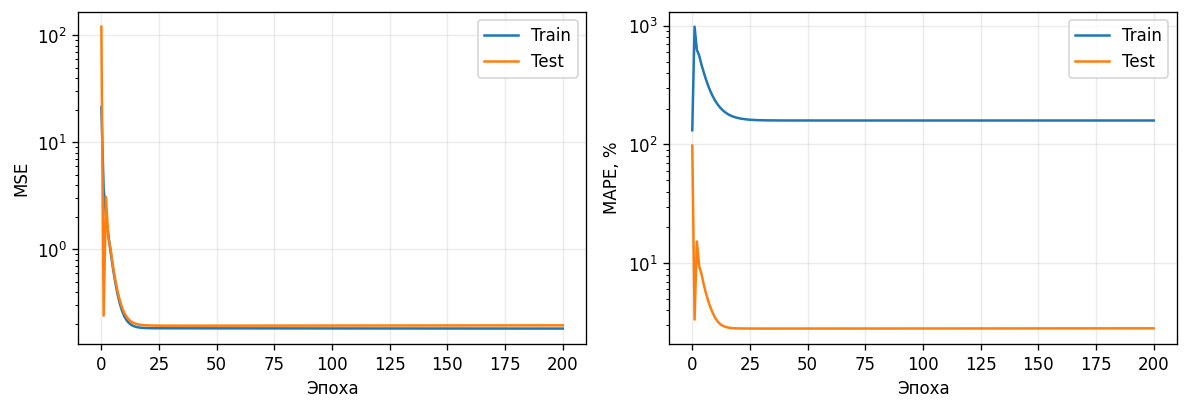

In [8]:
def evaluate_history(trajectory, Z_train, y_train, Z_test, y_test):
    history = {"train_mse": [], "test_mse": [], "train_mape": [], "test_mape": []}
    for w, b in trajectory:
        pred_train = predict(Z_train, w, b)
        pred_test = predict(Z_test, w, b)
        history["train_mse"].append(mse(y_train, pred_train))
        history["test_mse"].append(mse(y_test, pred_test))
        history["train_mape"].append(mape(y_train, pred_train))
        history["test_mape"].append(mape(y_test, pred_test))
    return history


def plot_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for ax, metric, label in zip(axes, ["mse", "mape"], ["MSE", "MAPE, %"]):
        ax.plot(history[f"train_{metric}"], label="Train")
        ax.plot(history[f"test_{metric}"], label="Test")
        ax.set(xlabel="Эпоха", ylabel=label, yscale="log")
        ax.grid(alpha=0.25)
        ax.legend()
    fig.tight_layout()
    plt.show()


LR = 0.1
EPOCHS = 200
w, b, trajectory = fit(Z_train, y_train, LR, EPOCHS)
history = evaluate_history(trajectory, Z_train, y_train, Z_test, y_test)
assert len(trajectory) == EPOCHS + 1
print("Веса:", w.round(4))
print(f"Смещение: {b:.4f}")
plot_history(history)

Сопоставим прогноз с наблюдаемым рядом и чистым трендом. Чистый тренд известен благодаря генерации данных. Метрики считаем относительно наблюдаемого ряда с шумом.

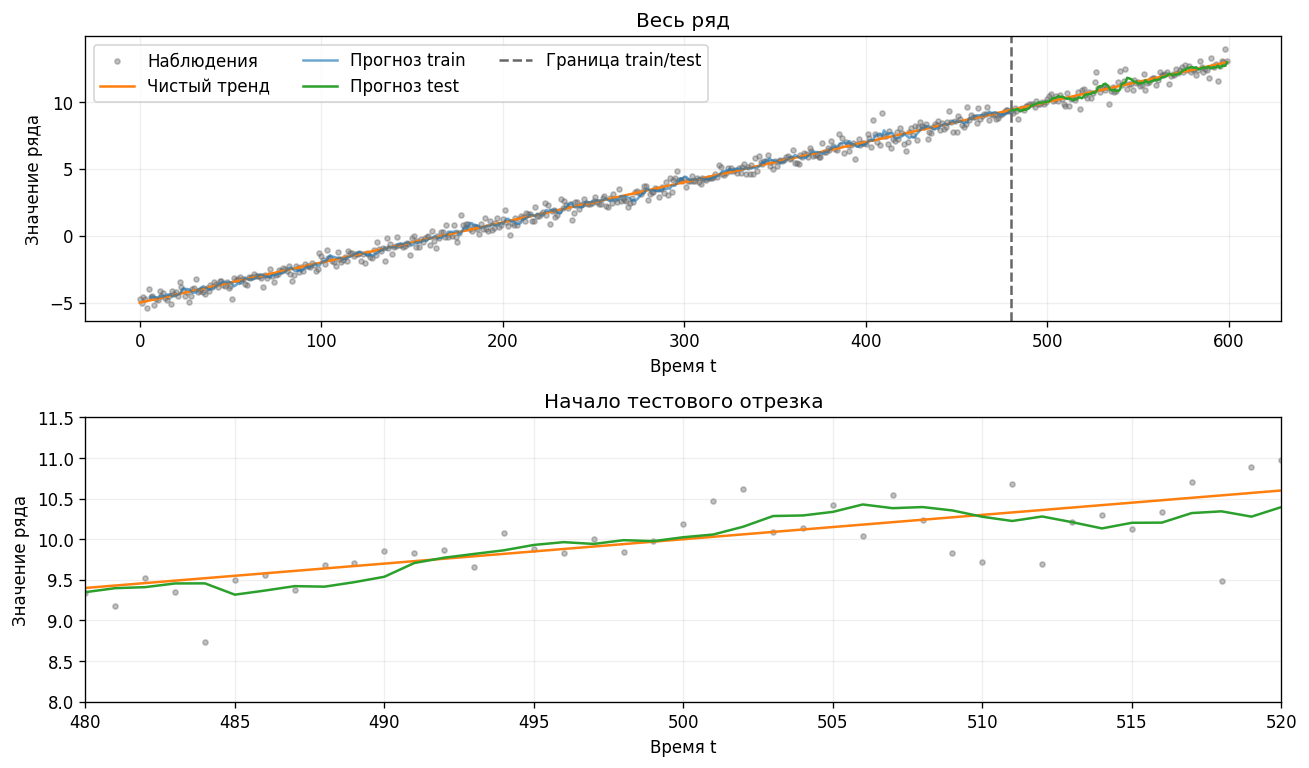

In [9]:
pred_train = predict(Z_train, w, b)
pred_test = predict(Z_test, w, b)

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5))
for ax in axes:
    ax.scatter(t, signal, s=9, alpha=0.4, color="0.4", label="Наблюдения")
    ax.plot(t, clean_signal, color="tab:orange", label="Чистый тренд")
    ax.plot(t_train, pred_train, color="tab:blue", alpha=0.65, label="Прогноз train")
    ax.plot(t_test, pred_test, color="tab:green", label="Прогноз test")
    ax.set(xlabel="Время t", ylabel="Значение ряда")
    ax.grid(alpha=0.2)
axes[0].axvline(SPLIT_AT, color="0.4", linestyle="--", label="Граница train/test")
axes[0].legend(ncols=3)
axes[0].set_title("Весь ряд")
axes[1].set(xlim=(480, 520), ylim=(8.0, 11.5), title="Начало тестового отрезка")
fig.tight_layout()
plt.show()

Вернёмся к лабе 3. МНК и градиентный спуск минимизируют одну и ту же сумму квадратов с точностью до постоянного делителя $n$. Добавим к входам столбец единиц для смещения и найдём контрольное решение через `np.linalg.lstsq`. Для сравнения возьмём простой прогноз по последнему наблюдению окна.

In [10]:
A_train = np.column_stack((Z_train, np.ones(len(Z_train))))
w_ref_and_b, *_ = np.linalg.lstsq(A_train, y_train, rcond=None)
w_ref, b_ref = w_ref_and_b[:-1], w_ref_and_b[-1]

models = [
    ("Градиентный спуск", pred_train, pred_test),
    ("МНК", predict(Z_train, w_ref, b_ref), predict(Z_test, w_ref, b_ref)),
    ("Последнее наблюдение", X_train[:, -1], X_test[:, -1]),
]
print(f"{'Модель':<24} {'MSE train':>10} {'MSE test':>10} {'MAPE train':>12} {'MAPE test':>11}")
for name, train_pred, test_pred in models:
    print(f"{name:<24} {mse(y_train, train_pred):10.6f} {mse(y_test, test_pred):10.6f}"
          f" {mape(y_train, train_pred):11.2f}% {mape(y_test, test_pred):10.2f}%")

print(f"Наименьшие |y|: train = {abs(y_train).min():.6f}, test = {abs(y_test).min():.6f}")
print(f"Точные нули: train = {(y_train == 0).sum()}, test = {(y_test == 0).sum()}")

Модель                    MSE train   MSE test   MAPE train   MAPE test
Градиентный спуск          0.181718   0.194901      159.26%       2.82%
МНК                        0.180378   0.201840      159.34%       2.90%
Последнее наблюдение       0.305541   0.302005       78.87%       3.72%
Наименьшие |y|: train = 0.001200, test = 8.731171
Точные нули: train = 0, test = 0


При 200 эпохах тестовая MSE у обученного нейрона около $0.195$, у прогноза последним наблюдением около $0.302$. На увеличенном графике прогноз следует за ростом ряда и сглаживает часть резких отклонений. Train MAPE выше $100\%$, потому что в обучающих целях есть значения, близкие к нулю. Это тот же эффект, который встретился в лабе 3.

## 7. Эксперименты

### Скорость обучения

Сравним $\eta=0.001$, $0.1$ и $0.17$ при 60 эпохах. Зафиксируем начальные веса и данные. Логарифмическая шкала MSE позволяет увидеть все три кривые на одном рисунке.

     Шаг    MSE train     MSE test
   0.001     7.688228    38.697583
     0.1     0.182554     0.193564
    0.17   302.223719  1430.934977


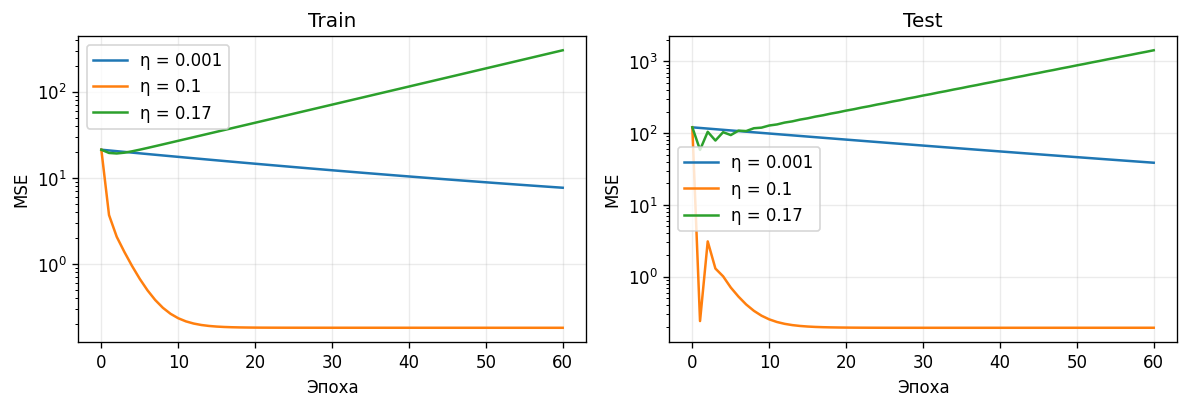

In [11]:
rates = (0.001, 0.1, 0.17)
rate_epochs = 60
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

print(f"{'Шаг':>8} {'MSE train':>12} {'MSE test':>12}")
for rate in rates:
    _, _, run = fit(Z_train, y_train, rate, rate_epochs)
    run_history = evaluate_history(run, Z_train, y_train, Z_test, y_test)
    for ax, split in zip(axes, ["train", "test"]):
        ax.plot(run_history[f"{split}_mse"], label=f"η = {rate:g}")

    print(f"{rate:8g} {run_history['train_mse'][-1]:12.6f} {run_history['test_mse'][-1]:12.6f}")

for ax, split in zip(axes, ["Train", "Test"]):
    ax.set(title=split, xlabel="Эпоха", ylabel="MSE", yscale="log")
    ax.grid(alpha=0.25)
    ax.legend()

fig.tight_layout()
plt.show()

При малом шаге ошибка ещё снижается к 60-й эпохе. При $\eta=0.1$ она быстро приближается к плато. При $\eta=0.17$ ошибка растёт. Такой шаг вызывает расходимость на этой матрице входов.

### Число эпох

Теперь фиксируем шаг $\eta=0.1$ и сравниваем 5, 40 и 200 эпох. Данные и начальные параметры снова одни и те же.

    Эпох    MSE train     MSE test
       5     0.673490     0.703632
      40     0.182711     0.193374
     200     0.181718     0.194901


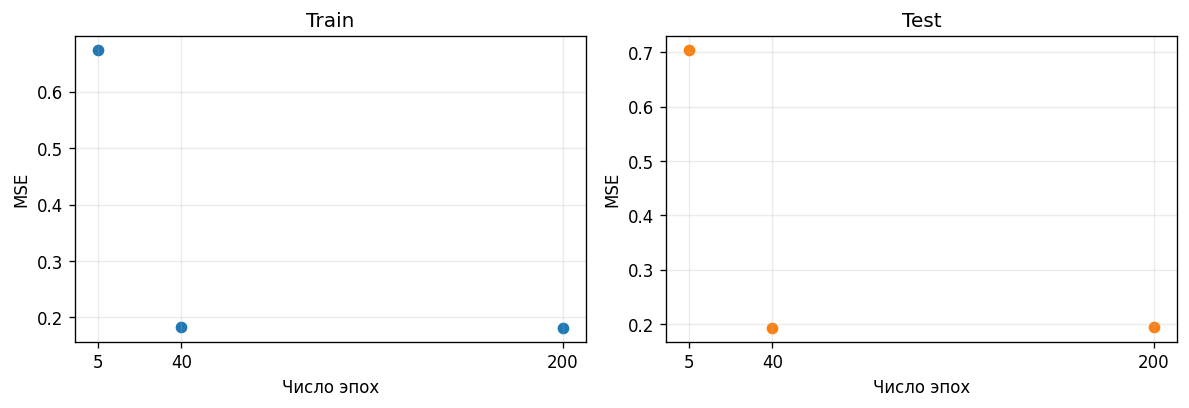

In [12]:
epoch_counts = (5, 40, 200)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

print(f"{'Эпох':>8} {'MSE train':>12} {'MSE test':>12}")
for count in epoch_counts:
    _, _, run = fit(Z_train, y_train, LR, count)
    run_history = evaluate_history(run, Z_train, y_train, Z_test, y_test)
    train_loss = run_history["train_mse"][-1]
    test_loss = run_history["test_mse"][-1]
    axes[0].scatter(count, train_loss, color="tab:blue")
    axes[1].scatter(count, test_loss, color="tab:orange")
    print(f"{count:8d} {train_loss:12.6f} {test_loss:12.6f}")

for ax, split in zip(axes, ["Train", "Test"]):
    ax.set(title=split, xlabel="Число эпох", ylabel="MSE", xticks=epoch_counts)
    ax.grid(alpha=0.25)

fig.tight_layout()
plt.show()

С 5 до 40 эпох улучшаются обе MSE. С 40 до 200 эпох обучающая ошибка уменьшается примерно на $0.001$, тестовая растёт примерно на $0.0015$. В этом запуске заметное улучшение произошло на ранних эпохах. Для выбора числа эпох в рабочей задаче выделили бы валидационный отрезок перед test и сравнивали настройки по нему.

## 8. Вопросы для защиты

1. Что такое переобучение и как его избежать в задаче регрессии?
2. Почему важно нормализовать входы перед обучением?
3. Как связана скорость обучения со сходимостью?
4. Может ли один линейный нейрон аппроксимировать любую функцию?
5. Как по графикам заметить недообучение или переобучение?


<details>
<summary>Ответы</summary>

1. Переобученная модель подстраивается под детали обучающей выборки, которые плохо переносятся на новые данные. Помогают подходящая сложность модели, регуляризация и выбор настроек по валидационному отрезку.
2. Стандартизация даёт признакам сопоставимый масштаб. Одна скорость обучения тогда лучше подходит для обновления разных весов. Похожие лаги могут оставаться сильно коррелированными.
3. Малый шаг может требовать многих эпох. Подходящий шаг снижает MSE. Слишком большой шаг переносит параметры через минимум так далеко, что MSE начинает расти.
4. При фиксированных шести входах выход — взвешенная сумма и смещение. Он может приблизить ряд, если следующее значение связано с лагами примерно линейно. Произвольная нелинейная зависимость потребует преобразования признаков или модели с нелинейными активациями.
5. Если обе ошибки велики и модель пропускает заметную закономерность, ей может не хватать эпох или выразительности. Длительное падение train MSE при росте ошибки на валидации указывает на возможное переобучение. Один небольшой разрыв может возникнуть из-за различий между отрезками ряда.

</details>